In [40]:
%load_ext autoreload
%autoreload 2
import xarray as xr
import numpy as np
import matplotlib.pyplot as plt
import xr_ccew as tw
from src.noaa_olr import (
    load_noaa_olr
)

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


In [33]:
olr = load_noaa_olr(
    lat_range=(-20, 20),
    time_range=("1990-01-01", "2010-12-31")
)

olr_anom = (
    tw.remove_mean_and_linear_trend(
        tw.remove_harmonics_of_seasonal_cycle(
            olr,
            num_harmonics=3
        )
    )
)

Wheeler Kiladis diagram

In [26]:
GENERAL_KELVIN = tw.WaveProfile(
    name="KW",
    aliases=("Kelvin", "Kelvin wave"),
    k_min=1,
    k_max=14,
    frequency_min=1.0 / 30.0,
    frequency_max=1.0 / 2.5,
    equivalent_depth_min=1,
    equivalent_depth_max=200,
    symmetry="symmetric",
    direction="eastward",
    curve_name="kelvin",
    description="Convectively coupled Kelvin wave.",
)

In [56]:
wave_data = tw.filter_field(olr_anom, GENERAL_KELVIN)

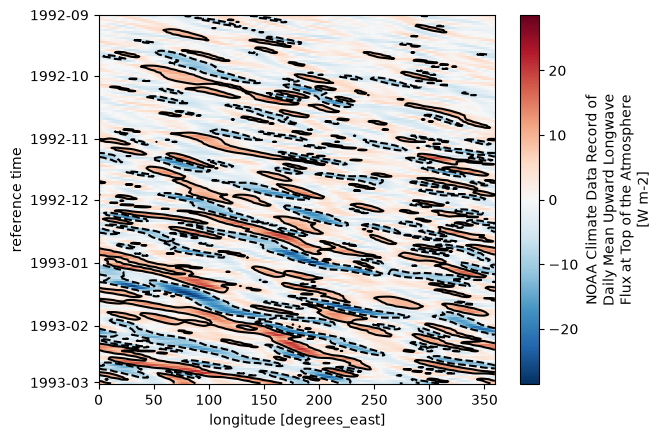

In [58]:
hovmoller_wave_data = wave_data.mean("lat")
mask = abs(hovmoller_wave_data) >= hovmoller_wave_data.std()

fig, ax = plt.subplots()
data_to_plot = hovmoller_wave_data.sel(time=slice("1992-09-01", "1993-03-01"))
data_to_plot.plot(
    y="time",
    ax=ax
)

data_to_plot.plot.contour(
    levels=[-hovmoller_wave_data.std(), hovmoller_wave_data.std()],
    colors='k'
)

ax.invert_yaxis()
